# Figure 4: November 2 submission

Rebuild the current figure panels from saved local results. The final reference cell shows the exact image in the November 2, 2026 submission package.


## Run the notebook

Use the R kernel. Start in the repository root. Set `QTL_PAPER_ROOT` to the local
paper directory and `QTL_SOURCE_ROOT` to the figure checkout with staged inputs
and saved objects. For example, set these variables in the R session before
you run the cells. Paths can contain spaces.

Run the cells from top to bottom. The notebook reads the recorded figure data.
It does not rerun upstream QTL mapping unless a section explicitly says so.
New PDFs and PNGs go to `notebook_outputs/`. Inputs stay in place.
The source scripts are in `notebooks/current/`. Figures shown below are aggregate
plots. Do not print participant tables into a saved notebook.


## Scope

The code rebuilds plots from saved results. It does not repeat the upstream QTL analysis.

The archived submission image is a reference. See each section for the code and the scope of the plot reconstruction.


## Setup

Validate the local input paths and load the plot libraries.


In [1]:
# Shared setup for the November 2 figure notebooks.
suppressPackageStartupMessages({
  library(tidyverse)
  library(patchwork)
})
if (requireNamespace("showtext", quietly = TRUE)) showtext::showtext_auto(FALSE)

paper_root <- Sys.getenv("QTL_PAPER_ROOT")
source_root <- Sys.getenv("QTL_SOURCE_ROOT", getwd())
notebook_output <- Sys.getenv("QTL_NOTEBOOK_OUTPUT", file.path(getwd(), "notebook_outputs"))
input_records <- new.env(parent = emptyenv())

checked_input <- function(root, relative, variable) {
  if (!nzchar(root)) stop("Set ", variable, " before you run this notebook.", call. = FALSE)
  if (grepl("^(gs|s3|https?)://", root)) {
    stop("Input localization error: ", variable, " must be a local directory.", call. = FALSE)
  }
  path <- file.path(root, relative)
  if (!file.exists(path) || file.access(path, 4) != 0) {
    stop("Missing or unreadable input: ", relative, ". Check ", variable, ".", call. = FALSE)
  }
  path <- normalizePath(path, mustWork = TRUE)
  input_records[[paste(variable, relative, sep = ":")]] <- list(
    root = variable, path = relative, md5 = unname(tools::md5sum(path)))
  path
}
paper_file <- function(relative) checked_input(paper_root, relative, "QTL_PAPER_ROOT")
source_file <- function(relative) checked_input(source_root, relative, "QTL_SOURCE_ROOT")
output_file <- function(relative) {
  path <- file.path(notebook_output, relative)
  dir.create(dirname(path), recursive = TRUE, showWarnings = FALSE)
  path
}

save_plot <- function(plot, name, width_mm = 180, height_mm = 130) {
  message("Export aggregate plot: ", name)
  for (extension in c("pdf", "png")) {
    ggplot2::ggsave(output_file(paste0(name, ".", extension)), plot,
                   width = width_mm, height = height_mm, units = "mm", dpi = 180,
                   device = if (extension == "pdf") grDevices::cairo_pdf else "png",
                   bg = "white", limitsize = FALSE)
  }
  invisible(plot)
}

display_image <- function(path) {
  capture <- getOption("qtl.notebook.display")
  if (is.function(capture)) capture(path) else IRdisplay::display_png(file = path)
  invisible(NULL)
}
show_reference <- function(number) {
  path <- paper_file(paste0("output/Science_submission_package_20261102/Figures/Figure", number, ".png"))
  message("Display the archived November 2 submission image for Figure ", number, ".")
  display_image(path)
}

theme_set(theme_classic(base_size = 9) +
            theme(plot.title = element_blank(), plot.subtitle = element_blank(),
                  legend.title = element_blank(), panel.grid = element_blank()))
options(repr.plot.width = 10, repr.plot.height = 7, repr.plot.res = 150)
message("Current figure setup loaded. Inputs are read in place; outputs use notebook_outputs/.")


Current figure setup loaded. Inputs are read in place; outputs use notebook_outputs/.


## Read current panel objects

This code reproduces the Science print-size changes from the current saved panels. Source test results are retained.


In [2]:
#!/usr/bin/env Rscript
# Set Figure 4 text sizes at its final print width. Use the saved plot data.
suppressPackageStartupMessages({
  library(tidyverse)
  library(patchwork)
  library(ggh4x)
  library(svglite)
})

p <- set_names(c("A_labeled", "B", "C", "D")) |>
  map(\(name) readRDS(source_file(paste0("Fig4/objects/", name, ".rds"))))

# Use device fonts so PDF and SVG text stays editable.
font <- "Helvetica"
pt_per_mm <- 72.27 / 25.4
base_theme <- theme(
  line = element_line(linewidth = 0.25),
  axis.line = element_line(linewidth = 0.25),
  axis.ticks = element_line(linewidth = 0.25),
  text = element_text(family = font, size = 7),
  axis.text = element_text(size = 6, colour = "black"),
  axis.text.x = element_text(size = 6),
  axis.text.y = element_text(size = 6),
  axis.title = element_text(size = 7),
  strip.text = element_text(size = 7),
  strip.text.x = element_text(size = 7),
  legend.text = element_text(size = 6),
  legend.title = element_text(size = 7),
  plot.tag = element_text(size = 10, face = "bold", family = font),
  plot.tag.position = c(0, 1),
  plot.margin = margin(2, 2, 2, 2, unit = "pt")
)


## Trait categories and colocalization

Use the current saved count and lenient union-rate plot. Keep all 68 trait labels.


In [3]:
a <- p$A_labeled
label_layer <- which(map_lgl(a$layers, \(layer) inherits(layer$geom, "GeomText")))
stopifnot(length(label_layer) == 1L)
label_data <- a$layers[[label_layer]]$data
a$layers[[label_layer]]$aes_params$size <- 6 / pt_per_mm
a$layers[[label_layer]]$aes_params$family <- font
# Reserve more count-axis space for the larger labels. Data stay unchanged.
a$layers[[label_layer]]$data <- label_data |> mutate(x = 2000)
a <- a + base_theme + labs(tag = "A") + theme(
  axis.text.y = element_blank(),
  axis.ticks.y = element_blank(),
  strip.text.y.left = element_text(size = 6.5, angle = 0, hjust = 1),
  strip.text.x = element_text(size = 7, face = "bold"),
  panel.spacing.x = grid::unit(3, "pt"),
  panel.spacing.y = grid::unit(1.5, "pt"),
  plot.margin = margin(2, 5, 2, 2, unit = "pt")
) + ggh4x::facetted_pos_scales(x = list(
  scale_x_continuous(breaks = c(0, 400, 800, 1200)),
  scale_x_continuous(labels = \(x) paste0(x, "%"),
                     expand = expansion(mult = c(0, 0.08)))
))
a$layers[[3]]$aes_params$linewidth <- 0.2
a$layers[[4]]$aes_params$linewidth <- 0.15
a$layers[[5]]$aes_params$linewidth <- 0.15
a$layers[[6]]$aes_params$size <- 0.65
# The saved labelled plot has many count-axis ticks. Keep four readable ticks.
a$facet$params$force.cols <- grid::unit(c(3, 1.6), "null")


ℹ Overriding facetted scales may be unstable.

## Rare-variant prediction

Keep the source histogram bins and source limits. No TWAS model is refitted.


In [4]:
b <- p$B + base_theme + labs(tag = "B") + theme(
  axis.title.x = element_text(size = 8.7)
)
b$layers[[1]]$aes_params$linewidth <- 0.14


## Conditional TWAS comparison

Keep the saved QQ coordinates and matched-control results.


In [5]:
c <- p$C + base_theme + labs(tag = "C") + theme(
  panel.spacing.x = grid::unit(5, "pt"),
  axis.title = element_text(size = 8.7)
)
c$layers[[1]]$aes_params$linewidth <- 0.2
c$layers[[2]]$aes_params$size <- 0.4


## Gene-set enrichment

Keep the recorded odds ratios and confidence limits.


In [6]:
d <- p$D + base_theme + labs(tag = "D") +
  labs(x = "Odds ratio per unit increase in Z-score") + theme(
    axis.title.x = element_text(size = 7),
    legend.key.size = grid::unit(3, "mm")
  )
d$layers[[1]]$aes_params$linewidth <- 0.2
d$layers[[2]]$aes_params$linewidth <- 0.3
d$layers[[2]]$aes_params$fatten <- NULL
d$layers[[2]]$aes_params$size <- 0.65
d$layers[[2]]$aes_params$stroke <- 0.22

top_right <- (b | c) + plot_layout(widths = c(0.85, 1.5))
right <- wrap_elements(full = top_right) / d +
  plot_layout(heights = c(1, 0.75))
fig <- (a | right) + plot_layout(widths = c(1.1, 1))


## Render the current Figure 4

The layout is 184 x 190 mm with 6 pt trait labels. Scientific data and fitted values are unchanged.


Export aggregate plot: Fig4/Figure4_rebuilt


`stat_bin()` using `bins = 30`. Pick better value `binwidth`.

(`geom_bar()`).

ℹ Please use the `size` aesthetic instead.

`stat_bin()` using `bins = 30`. Pick better value `binwidth`.

(`geom_bar()`).

`stat_bin()` using `bins = 30`. Pick better value `binwidth`.

(`geom_bar()`).

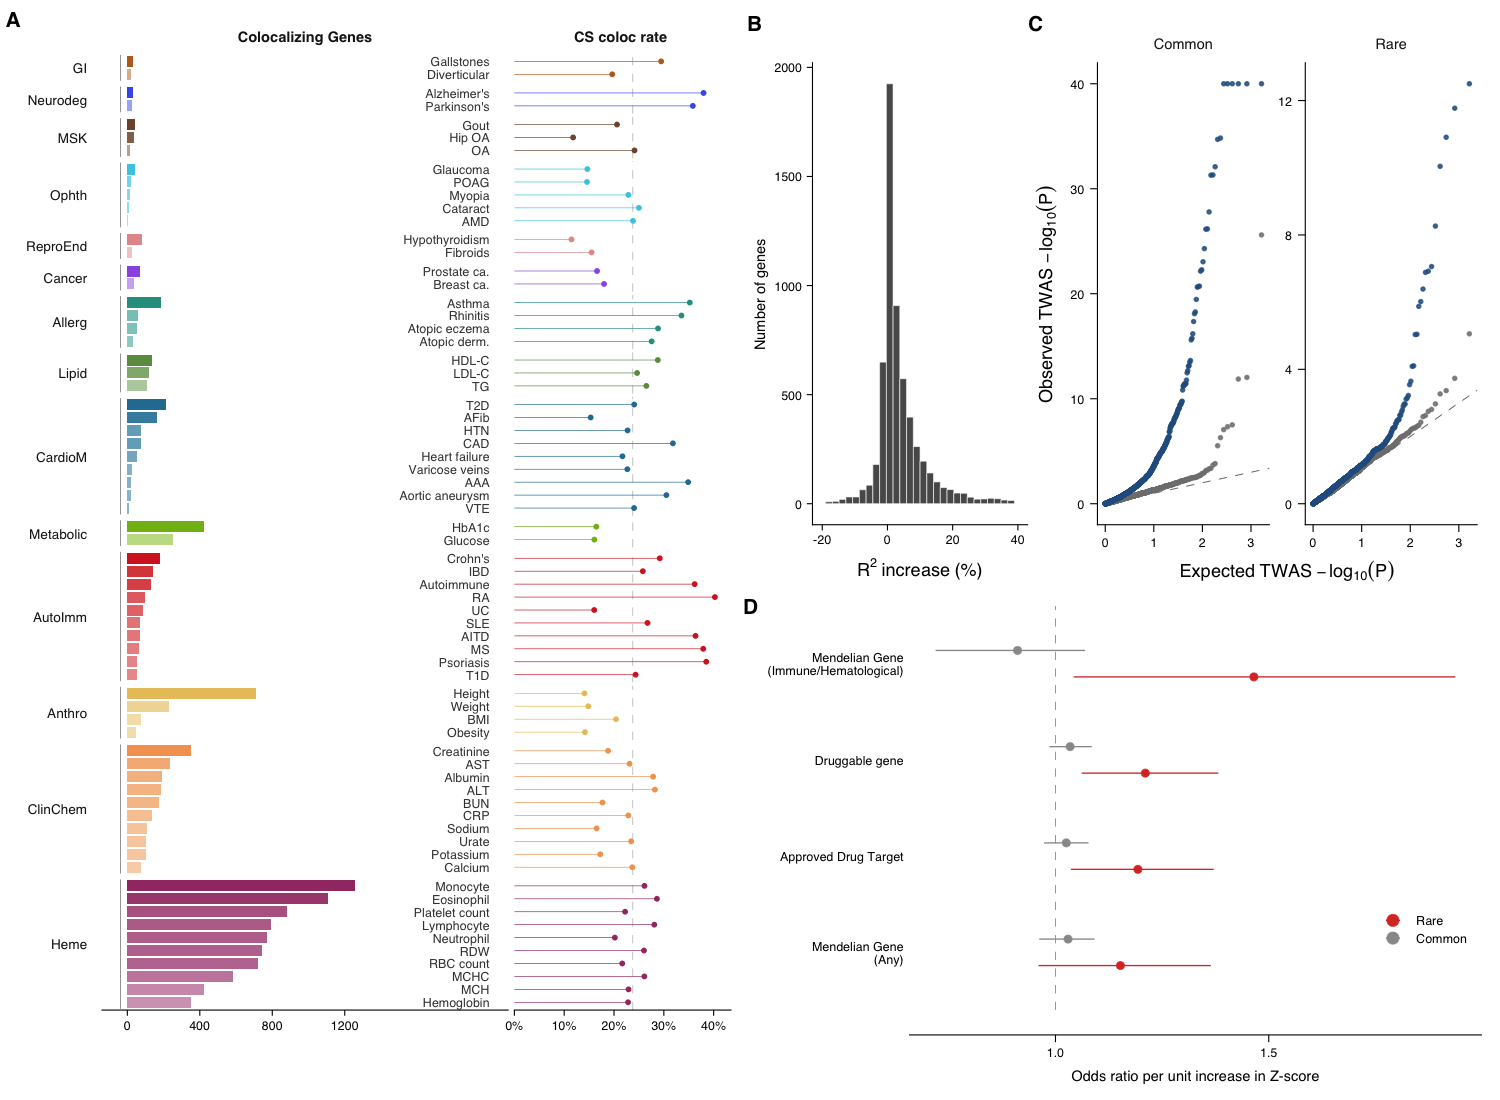

In [7]:
stopifnot(nrow(label_data) == 68L, identical(p$A_labeled$data, a$data))
save_plot(fig, "Fig4/Figure4_rebuilt", 184, 190)
print(fig)


## Exact submission reference

Display the exact archived image from the November 2 manuscript for comparison.


Display the archived November 2 submission image for Figure 4.


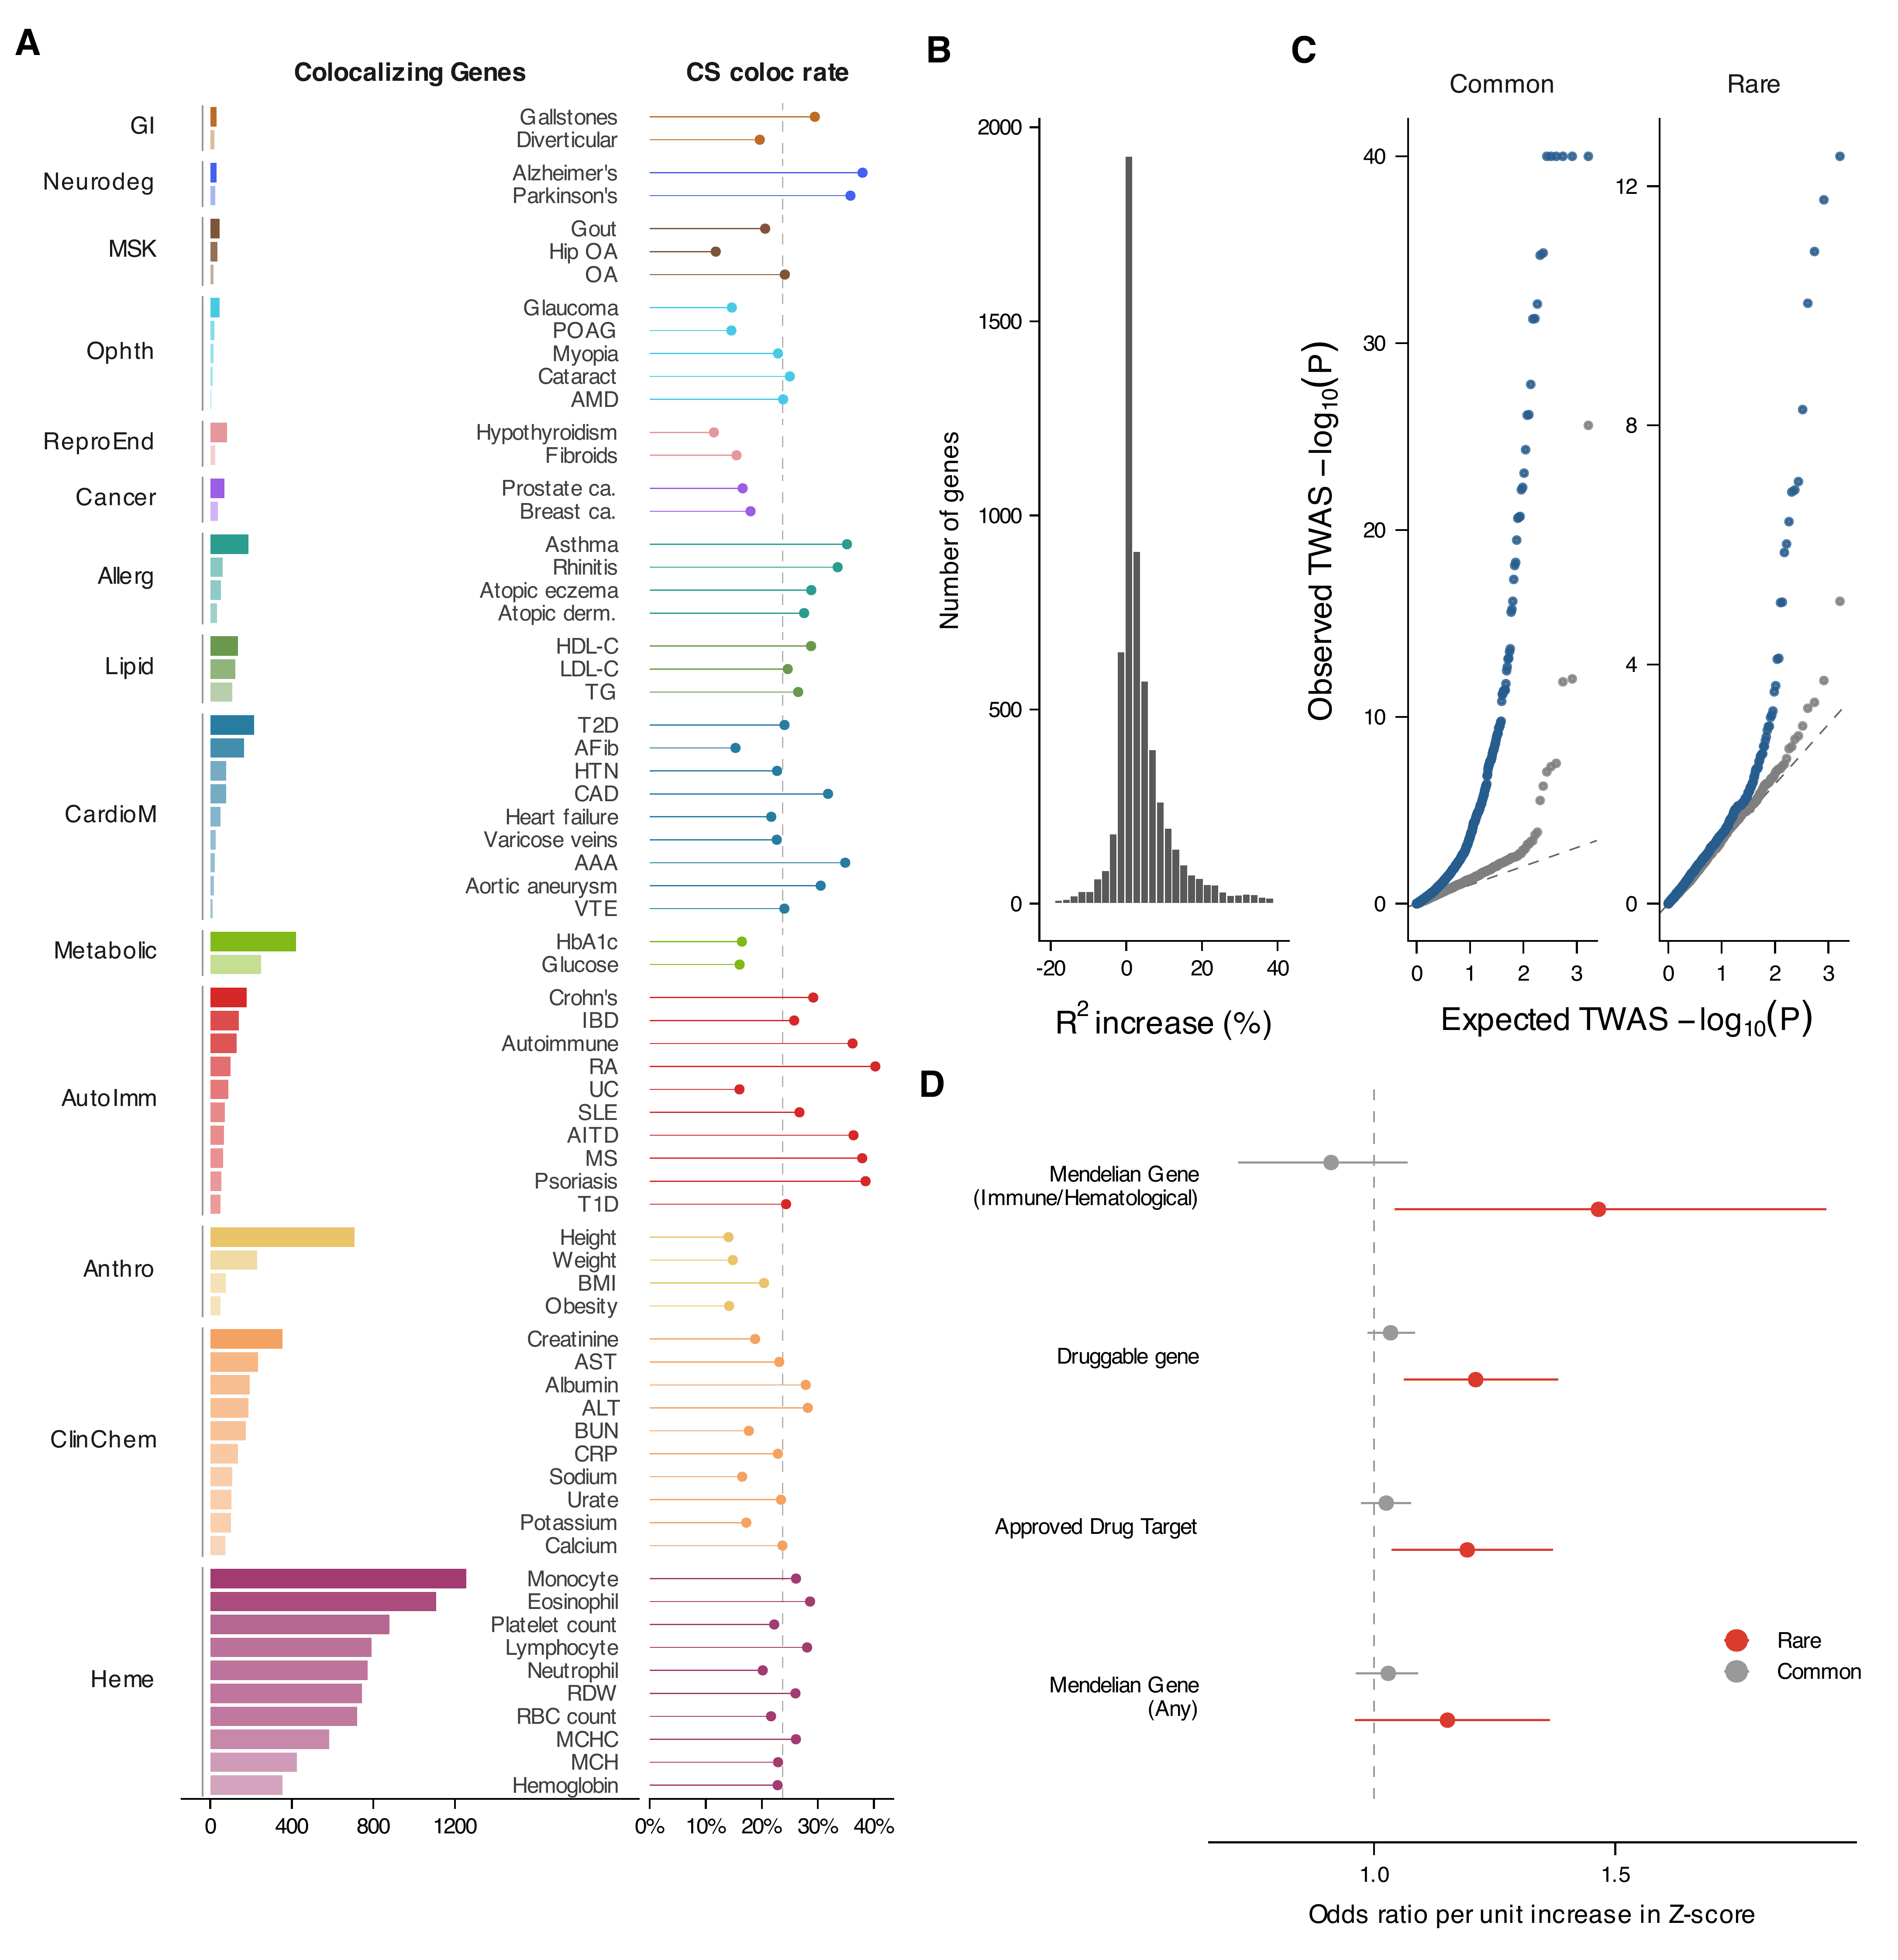

In [8]:
show_reference(4)
